In [30]:
from pathlib import Path
import numpy as np
import torch
from adabmDCA.fasta import get_tokens, import_from_fasta, compute_weights
from adabmDCA.stats import get_freq_single_point, get_freq_two_points
from adabmDCA.training import train_graph
from adabmDCA.functional import one_hot
from adabmDCA.utils import init_parameters, init_chains,get_dtype, get_mask_save
from adabmDCA.sampling import get_sampler
from adabmDCA.io import load_params,save_params, save_chains
from adabmDCA.resampling import compute_mixing_time
from adabmDCA.utils import resample_sequences
from adabmDCA.statmech import compute_energy
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

In [ ]:
import re
import RNA

def compute_Tm(sequences, tmin=0, tmax=150, tinc=1):
    T_m_list = []
    string_sequences = ["".join(tokens[i] for i in sequence) for sequence in sequences]
    for seq in string_sequences:
        fc = RNA.fold_compound(seq)
        results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)
        temperatures = []
        heat_capacities = []
        for result in results:
            # Convert the object to string
            result_str = str(result)
            # Parse the string (assuming format: RNA.RNA.heat_capacity_result(temperature="X", heat_capacity=Y))
            temp_str = float(re.split(r'[ ,"]', str(result))[3])
            hc_str = float(re.split(r'[ ,"]', str(result))[7])

            temperatures.append(temp_str)
            heat_capacities.append(hc_str)

        # Convert to NumPy arrays if needed
        temperatures = np.array(temperatures)
        heat_capacities = np.array(heat_capacities)
        argmax_hc = np.argmax(heat_capacities)
        T_m = temperatures[argmax_hc]
        T_m_list.append(T_m)

    return T_m_list



import re
import RNA

def compute_heat_capacity_single_seq(sequence, tmin, tmax, tinc=1):
    """
    Compute heat capacity for a given RNA sequence over a temperature range.

    Parameters:
    - sequence: Encoded sequence (list of integers corresponding to tokens).
    - tmin: Starting temperature for heat capacity calculation.
    - tmax: Ending temperature for heat capacity calculation.
    - tinc: Temperature increment (default 1).

    Returns:
    - temperatures: List of temperatures.
    - heat_capacities: List of corresponding heat capacities.
    """
    # Assuming tokens is defined globally (e.g., tokens = get_tokens("rna"))
    string_seq = "".join(tokens[i] for i in sequence)
    fc = RNA.fold_compound(string_seq)
    results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)
    temperatures = []
    heat_capacities = []
    for result in results:
        result_str = str(result)
        # Parse temperature and heat capacity from the string
        temp_str = float(re.split(r'[ ,"]', result_str)[3])
        hc_str = float(re.split(r'[ ,"]', result_str)[7])
        temperatures.append(temp_str)
        heat_capacities.append(hc_str)
    return temperatures, heat_capacities

# Example usage:
# temperatures, heat_capacities = compute_heat_capacity(sequences_NAT[0], 0, 150)




import RNA
import matplotlib.pyplot as plt
import numpy as np

RNA.cvar.temperature = 37


def compute_thermoscore(dot_bracket_structure, sequences_ART):
    tokens = get_tokens("rna")
    sequences_RNA = ["".join(tokens[i] for i in sequence) for sequence in sequences_ART]
    thermoscores = []
    for sequence in sequences_RNA:
        fc = RNA.fold_compound(sequence)
        thermoscore = -fc.eval_structure(dot_bracket_structure)
        thermoscores.append(thermoscore)
    return thermoscores


In [22]:
# Set the GPU device
device = "mps" 
dtype = get_dtype("float32")

In [32]:
# Select the alphabet correspondig to protein sequences
tokens = get_tokens("rna")

# Import the Natural MSA
path_data = "SAM_MSA.fasta"
headers, sequences_NAT = import_from_fasta(path_data, tokens=tokens, filter_sequences=True)
M, L, q = len(sequences_NAT), len(sequences_NAT[0]), len(tokens)

print(f"Number of sequences in the MSA: M={M}")
print(f"Length of the MSA: L={L}")
print(f"Number of Potts states: q={q}")

msa_enc = torch.tensor(sequences_NAT, device=device, dtype=torch.int32)
nat_sequences_one_hot = one_hot(msa_enc, num_classes=q).to(dtype)

Number of sequences in the MSA: M=10082
Length of the MSA: L=108
Number of Potts states: q=5


In [33]:
dot_bracket_structure = "((((((((....(((((...(((.....)))......)))))((((.((((((.......))))..))))))...(....((((((.....))))))..)))))))))" #RF00162
dot_bracked_alternative = "............(((((...(((.....)))......)))))((((.((((((.......))))..))))))...(....((((((.....))))))..)........"

len(dot_bracket_structure) == len(dot_bracked_alternative)

True

In [18]:
#Tms = compute_Tm(sequences_NAT, tmin=50, tmax=150)
Tms = np.loadtxt("SAM_Tms.txt")

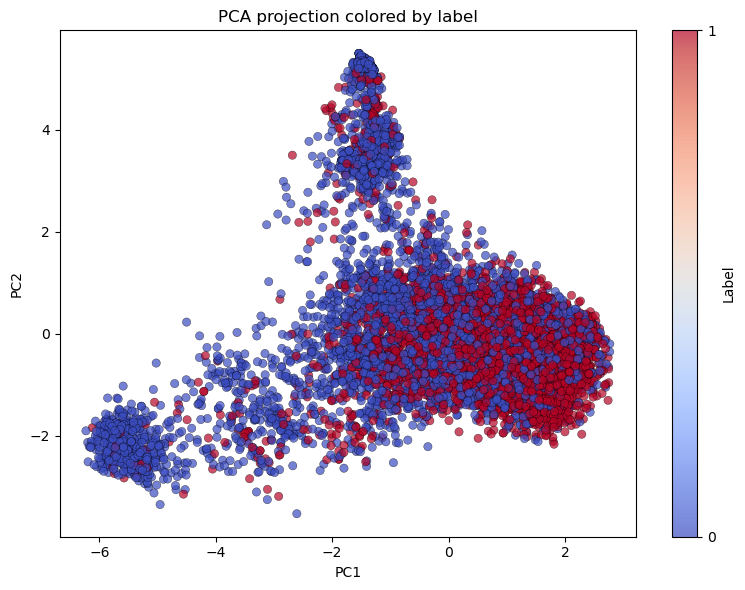

In [34]:
labels = (np.array(Tms) < 86).astype(np.int64)
X = nat_sequences_one_hot.view(M, -1).cpu().numpy()


# PCA projection colored by labels
pca = PCA(n_components=2, random_state=42)
proj = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(proj[:, 0], proj[:, 1], c=labels, cmap="coolwarm", alpha=0.7, edgecolor="k", linewidth=0.3)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA projection colored by label")
cbar = plt.colorbar(scatter, ticks=[0, 1])
cbar.set_label("Label")
plt.tight_layout()
plt.show()

In [35]:
X = nat_sequences_one_hot.view(M, -1).cpu().numpy()
Tms_array = np.array(Tms)

# Choose the number (e.g., 4 for range 82-90, change as needed)
delta = 4
center = 86
lower_bound = center - delta
upper_bound = center + delta

labels = (Tms_array < center).astype(np.int64)


# Filter sequences where Tm is between lower_bound and upper_bound
mask = (Tms_array <= lower_bound) | (Tms_array >= upper_bound)
X_filtered = X[mask]
y_filtered = labels[mask]

y = y_filtered

clf = RandomForestClassifier(n_estimators=100, random_state=42, oob_score=True)
clf = LogisticRegression(max_iter=1000, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_filtered, y_filtered, test_size=0.1, random_state=42)
clf.fit(X_train, y_train)

# print(f"OOB Score: {clf.oob_score_:.4f}")
test_score = clf.score(X_test, y_test)
print(f"Test Score: {test_score:.4f}")
train_score = clf.score(X_train, y_train)
print(f"Train Score: {train_score:.4f}")

Test Score: 0.7916
Train Score: 0.8171


In [39]:
import re
import RNA

def compute_heat_capacity_single_seq(sequence, tmin, tmax, tinc=1):
    """
    Compute heat capacity for a given RNA sequence over a temperature range.

    Parameters:
    - sequence: Encoded sequence (list of integers corresponding to tokens).
    - tmin: Starting temperature for heat capacity calculation.
    - tmax: Ending temperature for heat capacity calculation.
    - tinc: Temperature increment (default 1).

    Returns:
    - temperatures: List of temperatures.
    - heat_capacities: List of corresponding heat capacities.
    """
    # Assuming tokens is defined globally (e.g., tokens = get_tokens("rna"))
    string_seq = "".join(tokens[i] for i in sequence)
    fc = RNA.fold_compound(string_seq)
    results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)
    temperatures = []
    heat_capacities = []
    for result in results:
        result_str = str(result)
        # Parse temperature and heat capacity from the string
        temp_str = float(re.split(r'[ ,"]', result_str)[3])
        hc_str = float(re.split(r'[ ,"]', result_str)[7])
        temperatures.append(temp_str)
        heat_capacities.append(hc_str)
    return temperatures, heat_capacities

# Example usage:
# temperatures, heat_capacities = compute_heat_capacity(sequences_NAT[0], 0, 150)

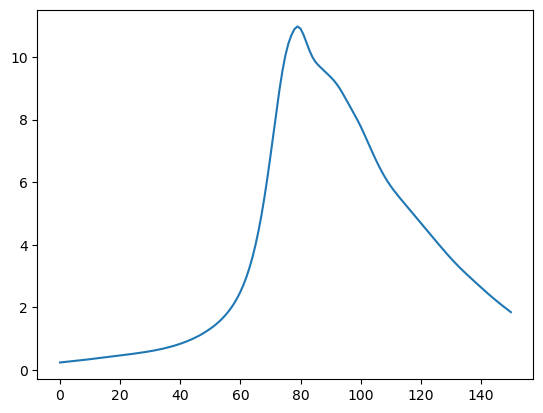

In [40]:
temperatures, heat_capacities = compute_heat_capacity_single_seq(sequences_NAT[0], 0, 150)
plt.plot(temperatures, heat_capacities)

In [41]:
import RNA
import matplotlib.pyplot as plt
import numpy as np

RNA.cvar.temperature = 37


def compute_thermoscore(dot_bracket_structure, sequences_ART):
    tokens = get_tokens("rna")
    sequences_RNA = ["".join(tokens[i] for i in sequence) for sequence in sequences_ART]
    thermoscores = []
    for sequence in sequences_RNA:
        fc = RNA.fold_compound(sequence)
        thermoscore = -fc.eval_structure(dot_bracket_structure)
        thermoscores.append(thermoscore)
    return thermoscores

In [ ]:
thermoscores = compute_thermoscore(dot_bracket_structure, sequences_NAT)

[27.0,
 19.399999618530273,
 22.100000381469727,
 -5.300000190734863,
 17.700000762939453,
 21.799999237060547,
 18.399999618530273,
 22.299999237060547,
 29.5,
 14.5,
 1.7999999523162842,
 23.799999237060547,
 30.399999618530273,
 5.300000190734863,
 -1.100000023841858,
 27.799999237060547,
 1.2999999523162842,
 -6.199999809265137,
 29.899999618530273,
 11.300000190734863,
 22.200000762939453,
 21.399999618530273,
 2.0,
 22.5,
 16.799999237060547,
 30.5,
 30.600000381469727,
 30.899999618530273,
 17.299999237060547,
 24.100000381469727,
 11.600000381469727,
 19.200000762939453,
 17.700000762939453,
 17.799999237060547,
 31.0,
 27.200000762939453,
 29.100000381469727,
 17.799999237060547,
 19.100000381469727,
 30.899999618530273,
 25.5,
 20.5,
 9.399999618530273,
 22.100000381469727,
 28.100000381469727,
 11.899999618530273,
 24.799999237060547,
 21.100000381469727,
 17.700000762939453,
 5.599999904632568,
 18.299999237060547,
 19.899999618530273,
 28.200000762939453,
 20.7999992370605